In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
df = pd.read_csv('german_credit_data (1).csv')

# understand the dataset

In [46]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [47]:
df.shape  # tell the no of rows and column

(1000, 11)

In [32]:
df.info()     # show datatype and null value count

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
dtypes: int64(5), str(5)
memory usage: 78.3 KB


In [48]:
df.columns.tolist()   # list of column name

['Unnamed: 0',
 'Age',
 'Sex',
 'Job',
 'Housing',
 'Saving accounts',
 'Checking account',
 'Credit amount',
 'Duration',
 'Purpose',
 'Risk']

In [49]:
df.describe()   # summerize numerical col

,Unnamed: 0,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


# check data quality

**Standarlize col name**

In [50]:
df.columns = df.columns.str.strip()      #remove extra space from col name

In [51]:
# Remove Unnamed columns
for col in df.columns:
    if col.startswith("Unnamed:"):
        df = df.drop(columns=[col])

In [52]:
# remove cust id if exists
for col in df.columns:
    if col.strip().lower() == "customer id" or col.strip().lower() =="customer_id" :
        df = df.drop(columns=[col])

In [53]:
df.shape
display(df.head())

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


**check missing values or duplicates**

In [39]:
df.isnull().sum()   # missing values

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64

In [40]:
(df.isnull().mean()*100).round(2)     # missing percentage

Age                  0.0
Sex                  0.0
Job                  0.0
Housing              0.0
Saving accounts     18.3
Checking account    39.4
Credit amount        0.0
Duration             0.0
Purpose              0.0
dtype: float64

In [41]:
df.duplicated().sum()

np.int64(0)

In [54]:
df['Risk'].value_counts(dropna=False)

Risk
good    700
bad     300
Name: count, dtype: int64

# EDA - Exploratery data Analytics

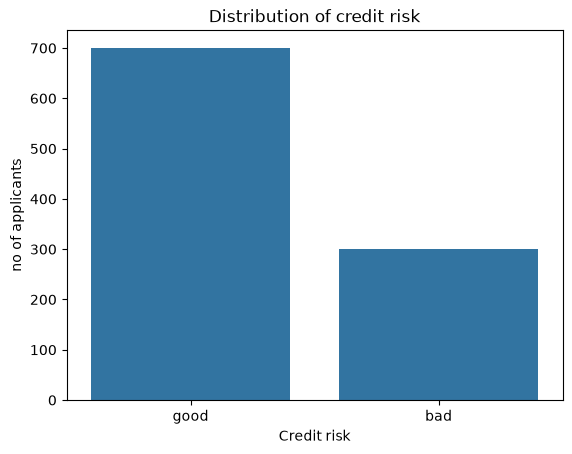

In [55]:
# good risk vs bad risk

sns.countplot(data=df , x='Risk')

plt.title("Distribution of credit risk")
plt.xlabel('Credit risk')
plt.ylabel('no of applicants')
plt.show()

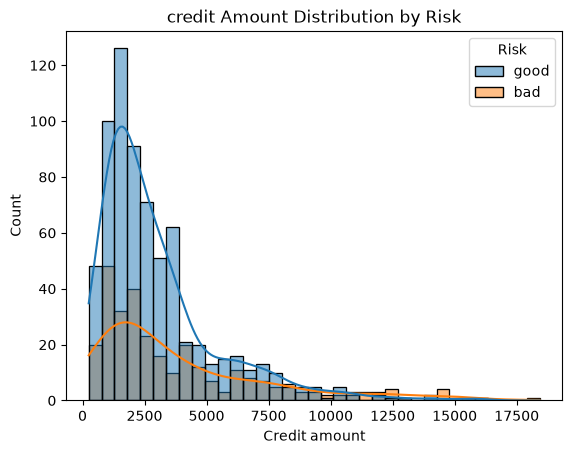

In [66]:
# credit amount 

sns.histplot(
    data = df,
    x = 'Credit amount',
    hue = 'Risk',
    kde = True
)
plt.title('credit Amount Distribution by Risk')
plt.show()

C:\Users\ANAMIKA\AppData\Local\Temp\ipykernel_1928\3690019467.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Text(0.5, 1.0, 'Loan Duration vs Credit Risk')

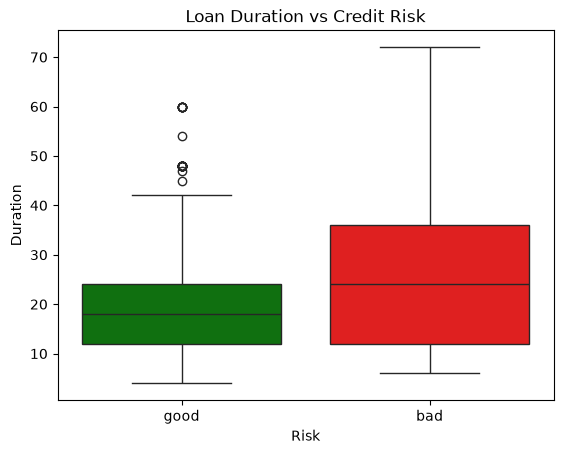

In [63]:
# compare loan duration 

sns.boxplot(
    data = df,
    x = 'Risk',
    y = 'Duration',
    palette={'good': 'green', 'bad': 'red'},
)
plt.title("Loan Duration vs Credit Risk")

Text(0.5, 1.0, 'housing status vs credit risk')

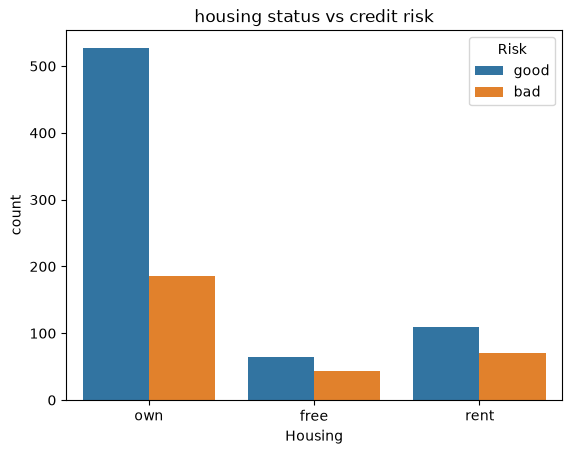

In [64]:
# Explore categorical variables

sns.countplot(
    data = df,
    x = 'Housing',
    hue = 'Risk'
)
plt.title("housing status vs credit risk")

# Feature Engineering

In [68]:
# add new column - feature 
df['Credit_per_month'] = (
    df['Credit amount']/df['Duration']
)

# display columns
display(
    df[
        ['Credit amount' , 'Duration' , 'Credit_per_month' , 'Risk']
    ].head()
)

,Credit amount,Duration,Credit_per_month,Risk
0,1169,6,194.833333,good
1,5951,48,123.979167,bad
2,2096,12,174.666667,good
3,7882,42,187.666667,good
4,4870,24,202.916667,bad


# Prepare the target and split the data

In [69]:
df = df.dropna(subset=['Risk']).copy()

In [70]:
df['Risk'] = (
    df['Risk']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'good':0 , 'bad':1})
)

In [ ]:
assert df['Risk'].notna().all(), (
        "Unexpected Risk labels found. Check the target values."
)

In [71]:
# seperate features and columns

x = df.drop(columns=['Risk'])
y = df['Risk'].astype(int)

In [75]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)


Training data: (800, 10)
Testing data: (200, 10)


# Preprocess the data

In [89]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.impute import SimpleImputer


# X_train ke andar numerical columns ke names ki list banata hai
numeric_features = x_train.select_dtypes(
    include='number'
).columns.tolist()

# X_train ke andar non-numerical columns ke names ki list banata hai
categorical_features = x_train.select_dtypes(
    exclude='number'
).columns.tolist()

# Numerical columns ke liye preprocessing pipeline banate hain
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler' , StandardScaler())
])

# Categorical columns ke liye preprocessing pipeline banate hain
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Numerical aur categorical pipelines ko combine karta hai
preprocessor = ColumnTransformer([
    ('num',numeric_pipeline , numeric_features),
    ('cat' , categorical_pipeline , categorical_features)
])

In [82]:
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'Job', 'Credit amount', 'Duration', 'Credit_per_month']
Categorical features: ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']


# train the machine learning model

In [91]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=5,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        class_weight='balanced',
        random_state=42
    )
}

trained_model = {}

for name, classifier in models.items():
    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', classifier)
    ])

    model.fit(x_train, y_train)
    trained_model[name] = model

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


# Evaluate your trained models

In [92]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [98]:
results = []

for name , model in trained_model.items():

    y_pred = model.predict(x_test)
    y_prob = model.predict_proba(x_test)[: ,1]

    results.append({
        'Model' : name , 
        'Precision':precision_score(
            y_test , y_pred , zero_division=0
        ),
        'Recall':recall_score(
            y_test , y_pred , zero_division = 0
        ),
        'F1-Score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(
    results_df
    .sort_values(by='F1-Score' , ascending=False)
    .round(3)
)

,Model,Precision,Recall,F1-Score,ROC-AUC
2,Random Forest,0.459,0.567,0.507,0.687
1,Decision Tree,0.400,0.667,0.500,0.631
0,Logistic Regression,0.398,0.550,0.462,0.622


# Visualize model performance

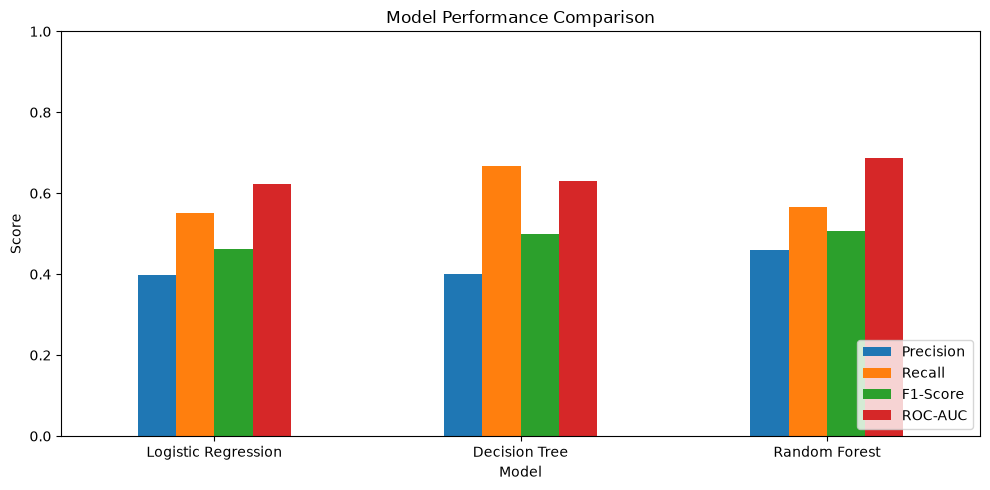

In [104]:
import matplotlib.pyplot as plt

metrics = ['Precision', 'Recall', 'F1-Score', 'ROC-AUC']

results_df.set_index('Model')[metrics].plot(
    kind = 'bar',
    figsize = (10,5)
)
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Confusion matrices

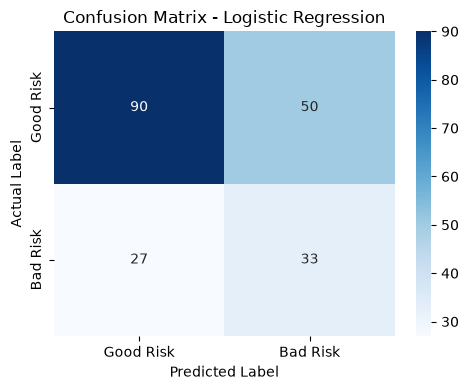

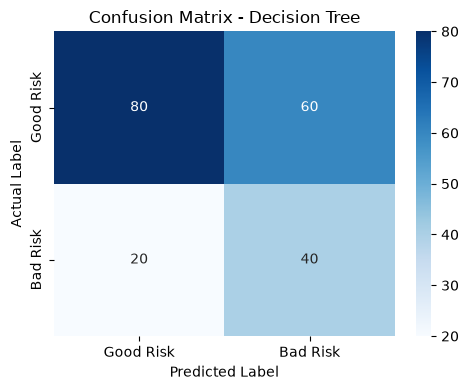

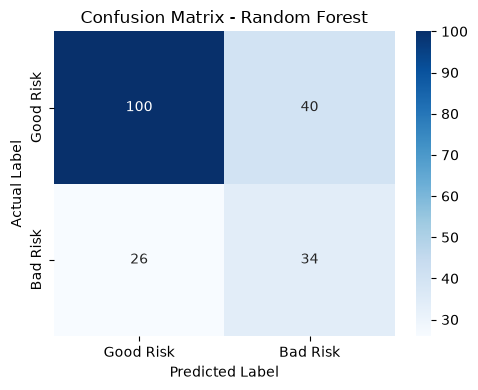

In [106]:
from sklearn.metrics import confusion_matrix

for name, model in trained_model.items():

    y_pred = model.predict(x_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Good Risk', 'Bad Risk'],
        yticklabels=['Good Risk', 'Bad Risk']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.tight_layout()
    plt.show()

# ROC curves

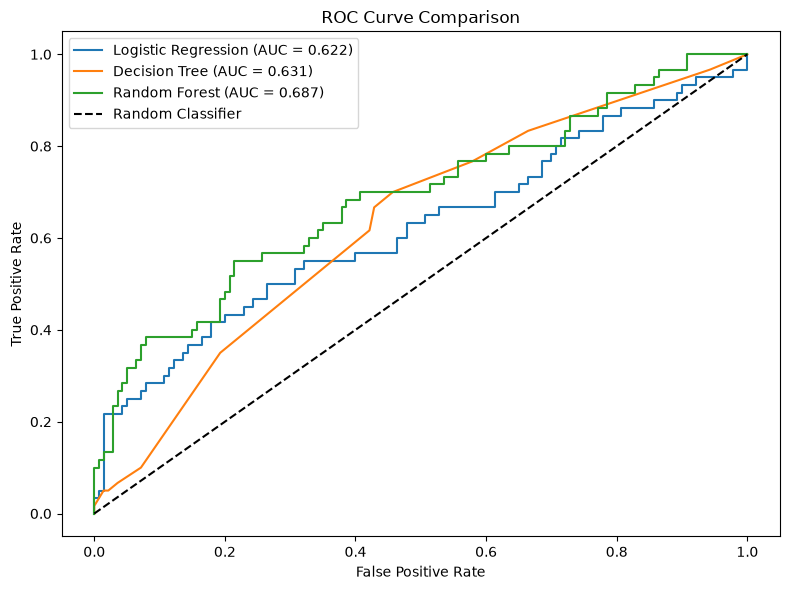

In [107]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

for name, model in trained_model.items():

    y_prob = model.predict_proba(x_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc:.3f})'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.show()

# save the best model

In [108]:
import joblib

best_model = trained_model['Random Forest']

joblib.dump(best_model, 'credit_risk_model.pkl')

print("Model saved successfully!")

Model saved successfully!


# Test a new customer prediction

In [109]:
sample_customer = x_test.iloc[[0]]

prediction = best_model.predict(sample_customer)[0]

bad_risk_probability = best_model.predict_proba(
    sample_customer
)[0][1]

if prediction == 1:
    print("Prediction: Bad Risk")
else:
    print("Prediction: Good Risk")

print(
    f"Bad Risk Probability: {bad_risk_probability:.2%}"
)

Prediction: Good Risk
Bad Risk Probability: 30.84%


# Load the saved model and verify it

In [110]:
loaded_model = joblib.load('credit_risk_model.pkl')

prediction = loaded_model.predict(sample_customer)[0]

print("Loaded model prediction:", prediction)

Loaded model prediction: 0


In [111]:
import os

print("Current folder:", os.getcwd())
print(os.listdir())

Current folder: C:\Users\ANAMIKA\OneDrive\Desktop\codeAlfa
['.ipynb_checkpoints', 'credit_risk_model.pkl', 'german_credit_data (1).csv', 'german_credit_data.csv', 'Untitled.ipynb']


In [113]:
print("Input columns:")
print(x.columns.tolist())

print("\nColumn data types:")
print(x.dtypes)

print("\nSaved model exists:")
print(os.path.exists("credit_risk_model.pkl"))

Input columns:
['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Credit_per_month']

Column data types:
Age                   int64
Sex                     str
Job                   int64
Housing                 str
Saving accounts         str
Checking account        str
Credit amount         int64
Duration              int64
Purpose                 str
Credit_per_month    float64
dtype: object

Saved model exists:
True
